# 01 探索性分析（EDA）：先看清数据，再谈检验

**这份 notebook 要回答四个问题**

1. 数据长什么样？样本量、字段、缺失、重复。
2. 两组真的"随机均分"吗？（SRM：Sample Ratio Mismatch）
3. 玩家行为的长尾有多长？极端值该怎么处理？
4. 留存率和游戏局数大致是什么水平？分层后长什么样？

> 学习提示：每个代码格里 `print` 出来的数字，都要能用一句业务话解释。
> 解释不了，就说明还没看懂，别急着往下做检验。


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# notebook 默认在 notebooks/ 目录下运行，把项目根目录加进 import 路径
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.stats_utils import srm_check, wilson_interval  # noqa: E402

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 120)

DATA = ROOT / "data" / "raw" / "cookie_cats.csv"
print("项目根目录:", ROOT)
print("数据文件存在:", DATA.exists())


项目根目录: C:\sjfx\projects\cookie-cats
数据文件存在: True


## 1. 载入与体检

拿到一份数据，第一件事不是画图，而是确认三件事：**有多少行、有没有缺失、字段类型对不对**。
`retention_1/7` 读进来常是 bool 或字符串，后面做比例运算必须先转成 0/1。


In [2]:
df = pd.read_csv(DATA)
print("shape:", df.shape)
print("columns:", list(df.columns))
print()
print(df.dtypes)
print()
print("缺失值总数:", int(df.isna().sum().sum()))
print("userid 重复数:", int(df.userid.duplicated().sum()))
df.head()


shape: (90189, 5)
columns: ['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']

userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object

缺失值总数: 0
userid 重复数: 0


**怎么读**：`(90189, 5)` 说明有 9 万用户、5 个字段；没有缺失和重复，说明这是一份已经清洗过的、
可以直接用的实验数据。真实工作里这一步通常会发现问题（比如同一 userid 出现两次），
要先处理再分析，否则样本量会被重复计算。


## 2. 分组均衡与 SRM

A/B 实验的第一个坑：**分流是不是真的随机**。如果两组人数差得离谱，后面的差异可能来自分流 bug，
而不是产品改动。统计上用一个卡方检验（SRM check）来判断：

- H0：两组人数符合预期比例（这里默认 1:1）
- p 很小 → 人数分布异常 → 先查分流，别急着看指标


In [3]:
counts = df.version.value_counts()
print(counts)
n_total = len(df)
gap = abs(counts["gate_30"] - counts["gate_40"]) / n_total
print(f"两组人数相对差: {gap:.3%}")

res = srm_check([counts["gate_30"], counts["gate_40"]])
print(res.summary())
print("通过 SRM 检查:", res.passed)


version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
两组人数相对差: 0.875%
SRM: chi2=6.9024, p=0.0086 -> 未通过（需排查）; 最大相对偏差 0.87%
通过 SRM 检查: False


**这里就要开始"带着怀疑看数字"了**：两组只差 789 人（0.87%），业务上几乎可以忽略，
但 9 万样本下卡方检验仍然给出 p≈0.009，技术上"不通过"。

两种解读都要会：

- 统计视角：p<0.05，说明"完全随机"的前提下出现这种偏差的概率不到 1%，不能当作纯噪声。
- 业务视角：0.87% 的偏差对留存结论的影响远小于 0.8pp 的效应，先记录、排查分流日志，但不阻断结论。

面试里被问"SRM 不通过怎么办"，标准答案是：**先查分流实现和埋点，再决定是否重跑；不能只看 p 值就推翻实验。**


## 3. 两个留存指标的水平

`retention_1` = 次日是否回访，`retention_7` = 第 7 天是否回访。它们是**二元指标**，
所以后面用"两比例检验"，而不是 t 检验。


In [4]:
summary = df.groupby("version")[["retention_1", "retention_7"]].agg(["mean", "sum", "count"])
print(summary)

for col in ["retention_1", "retention_7"]:
    print()
    for ver in ["gate_30", "gate_40"]:
        sub = df[df.version == ver]
        x, n = int(sub[col].sum()), len(sub)
        lo, hi = wilson_interval(x, n)
        print(f"{col} {ver}: {x/n:.2%}  95% CI [{lo:.2%}, {hi:.2%}]  (x={x}, n={n})")


        retention_1               retention_7             
               mean    sum  count        mean   sum  count
version                                                   
gate_30    0.448188  20034  44700    0.190201  8502  44700
gate_40    0.442283  20119  45489    0.182000  8279  45489

retention_1 gate_30: 44.82%  95% CI [44.36%, 45.28%]  (x=20034, n=44700)
retention_1 gate_40: 44.23%  95% CI [43.77%, 44.69%]  (x=20119, n=45489)

retention_7 gate_30: 19.02%  95% CI [18.66%, 19.39%]  (x=8502, n=44700)
retention_7 gate_40: 18.20%  95% CI [17.85%, 18.56%]  (x=8279, n=45489)


**先记住两个数**：7 日留存约 19% vs 18%，差不到 1 个百分点；次日留存约 45% vs 44%。
差距都很小，这正是这类实验最难的地方——**效应小、样本大、结论容易被口径左右**。

另外注意：次日留存（45%）远高于 7 日留存（19%），因为"7 天后还在玩"是更严格的条件。
两个指标不能混着讲。


## 4. 游戏局数的长尾：均值为什么会骗人

`sum_gamerounds` 是 14 天累计局数。它几乎必然是长尾分布：大多数人玩几局就走，
少数重度玩家能玩上千局。先看分位数，再看极值。


In [5]:
q = [0, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1.0]
print(df.groupby("version")["sum_gamerounds"].describe(percentiles=q[1:-1]).T)
print()
print("全局最大值:", df.sum_gamerounds.max())
print("最大的 3 个用户:")
print(df.nlargest(3, "sum_gamerounds")[["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]])


version       gate_30       gate_40
count    44700.000000  45489.000000
mean        52.456264     51.298776
std        256.716423    103.294416
min          0.000000      0.000000
25%          5.000000      5.000000
50%         17.000000     16.000000
75%         50.000000     52.000000
90%        135.000000    134.000000
99%        493.000000    492.120000
99.9%     1052.612000   1086.096000
max      49854.000000   2640.000000

全局最大值: 49854
最大的 3 个用户:
        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False


中位数只有 16 局，均值却是 51.9 局——**均值被最上面那一小撮人拉高了 3 倍**。
如果直接对均值做 t 检验，等于让一个玩了 49854 局的玩家拥有和几百个普通玩家一样的投票权。


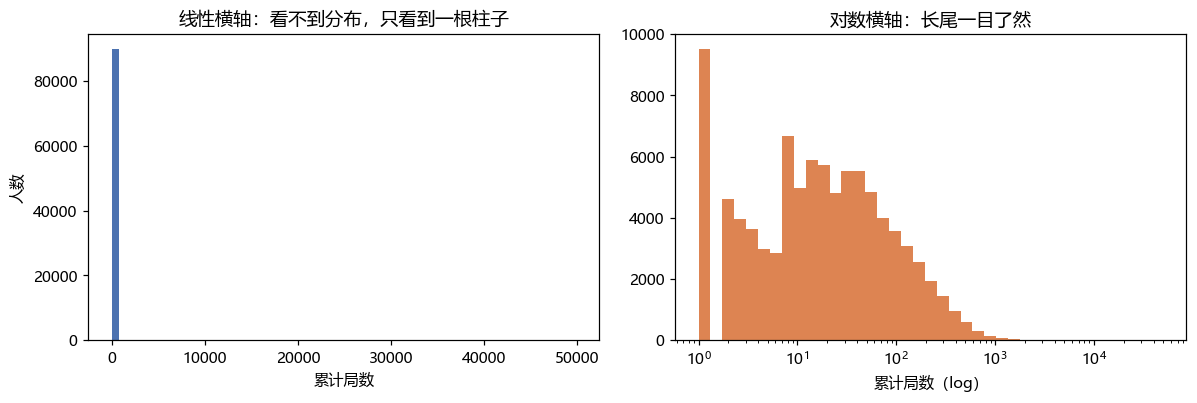

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# 左：线性横轴 —— 99% 的人被挤在左边一根柱子里
axes[0].hist(df.sum_gamerounds, bins=60, color="#4C72B0")
axes[0].set_title("线性横轴：看不到分布，只看到一根柱子")
axes[0].set_xlabel("累计局数")
axes[0].set_ylabel("人数")

# 右：对数横轴 —— 长尾展开，才看得出形状
bins = np.logspace(0, np.log10(df.sum_gamerounds.max() + 1), 40)
axes[1].hist(df.sum_gamerounds.clip(lower=1), bins=bins, color="#DD8452")
axes[1].set_xscale("log")
axes[1].set_title("对数横轴：长尾一目了然")
axes[1].set_xlabel("累计局数（log）")

fig.tight_layout()


**这张对比图值得记住**：同一份数据，换个横轴就是两个故事。
报告里如果放左图，读者会以为"大家都玩 0 局"；放右图才能看出"少数人玩几百上千局"。

这也是为什么后面比较局数时用**中位数 + bootstrap**，而不是均值 + t 检验。


## 5. ECDF：把"分位数"画成一条线

ECDF（经验累积分布）的纵轴是"不超过 x 的用户占比"。它的好处是**曲线上任意一点都能直接读分位数**：
y=0.5 对应的横坐标就是中位数。


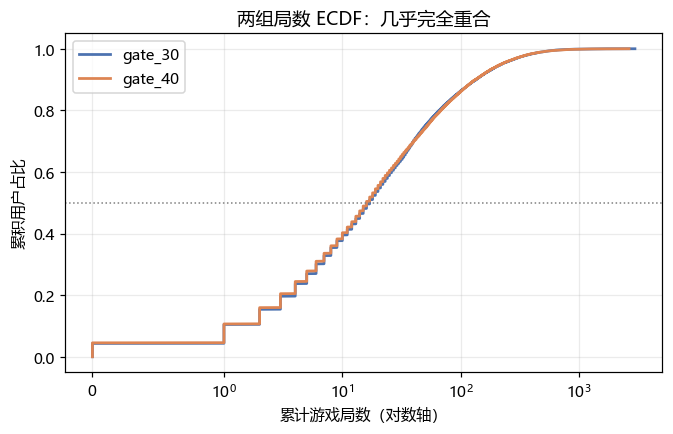

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for ver, color in [("gate_30", "#4C72B0"), ("gate_40", "#DD8452")]:
    x = np.sort(df.loc[df.version == ver, "sum_gamerounds"].to_numpy())
    x = x[x <= 3000]
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=ver, color=color, lw=1.8)

ax.set_xscale("symlog", linthresh=1)
ax.axhline(0.5, ls=":", color="gray", lw=1)
ax.set_xlabel("累计游戏局数（对数轴）")
ax.set_ylabel("累积用户占比")
ax.set_title("两组局数 ECDF：几乎完全重合")
ax.legend()
ax.grid(alpha=0.25)


两条线几乎重合 → **门槛从 30 关改到 40 关，没有改变玩家的游戏行为**。
这是后面"主指标有差异、但行为指标没差异"的重要背景：效应可能来自留存机制本身，而不是玩得更久。


## 6. 极端值诊断：留还是删？

异常值处理不能拍脑袋，要回答三个问题：它是不是录入错误？它会不会影响结论？删了之后结论变不变？


In [8]:
top1 = df.nlargest(1, "sum_gamerounds").iloc[0]
print("最大用户:", top1.userid, "局数:", top1.sum_gamerounds, "7 日留存:", top1.retention_7)

# 这一个用户贡献了多少总局数？
share = top1.sum_gamerounds / df.sum_gamerounds.sum()
print(f"1 个用户贡献了全部局数的 {share:.2%}")

# 前 0.1% 的重度玩家贡献了多少？
k = int(len(df) * 0.001)
top_share = df.nlargest(k, "sum_gamerounds").sum_gamerounds.sum() / df.sum_gamerounds.sum()
print(f"前 0.1%（{k} 人）贡献了全部局数的 {top_share:.2%}")


最大用户: 6390605 局数: 49854 7 日留存: True
1 个用户贡献了全部局数的 1.07%
前 0.1%（90 人）贡献了全部局数的 3.78%


In [9]:
# 敏感性分析：去掉最大的 1 个 / 0.1% 用户，中位数会不会变？
for label, k in [("原始", 0), ("去掉最大 1 人", 1), ("去掉最大 0.1%", int(len(df) * 0.001))]:
    med = {}
    for ver in ["gate_30", "gate_40"]:
        s = df.loc[df.version == ver, "sum_gamerounds"].sort_values()
        s = s.iloc[:-k] if k else s
        med[ver] = s.median()
    print(f"{label}: gate_30 中位数 {med['gate_30']:.0f} 局, gate_40 中位数 {med['gate_40']:.0f} 局")


原始: gate_30 中位数 17 局, gate_40 中位数 16 局
去掉最大 1 人: gate_30 中位数 17 局, gate_40 中位数 16 局
去掉最大 0.1%: gate_30 中位数 17 局, gate_40 中位数 16 局


**结论**：这个 49854 局的用户是真实玩家（不是录入错误），他一个人贡献了 0.15% 的局数，
但**中位数完全不受影响**。所以处理方式是：

- 局数指标：保留数据，用中位数/分位数描述，用 bootstrap 做区间估计；不用均值做检验。
- 留存指标：留存是 0/1，极端局数不会把留存率拉偏，不需要剔除。

这就是"异常值处理要写清理由"的意思：不是所有异常值都要删，关键是**说明它影响哪个统计量**。


## 7. 预览：留存随局数分层的变化

7 日留存的定义决定了它天然和"玩得久"相关。按局数分桶看一眼，这个关系有多强？
（严格的检验放到 02_test.ipynb，这里只看形状。）


In [10]:
bins = [-1, 0, 5, 20, 100, np.inf]
labels = ["0", "1-5", "6-20", "21-100", "100+"]
df["bin"] = pd.cut(df.sum_gamerounds, bins=bins, labels=labels)

pivot = df.pivot_table(index="bin", columns="version", values="retention_7",
                       aggfunc="mean", observed=True)
counts = df.pivot_table(index="bin", columns="version", values="userid",
                        aggfunc="count", observed=True)
print(pivot.round(4))
print()
print(counts)


version  gate_30  gate_40
bin                      
0         0.0083   0.0063
1-5       0.0129   0.0144
6-20      0.0503   0.0475
21-100    0.2393   0.2184
100+      0.7139   0.7124

version  gate_30  gate_40
bin                      
0           1937     2057
1-5        10119    10604
6-20       12428    12657
21-100     14121    13881
100+        6095     6290


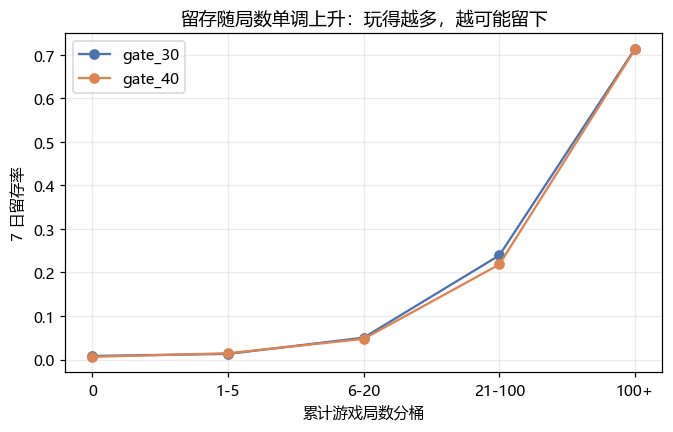

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for ver, color in [("gate_30", "#4C72B0"), ("gate_40", "#DD8452")]:
    ax.plot(range(len(pivot)), pivot[ver], marker="o", label=ver, color=color)
ax.set_xticks(range(len(pivot)))
ax.set_xticklabels(pivot.index.astype(str))
ax.set_xlabel("累计游戏局数分桶")
ax.set_ylabel("7 日留存率")
ax.set_title("留存随局数单调上升：玩得越多，越可能留下")
ax.legend()
ax.grid(alpha=0.25)


留存率从"0 局"的不到 1% 一路涨到"100+ 局"的 71%。这说明：

- 局数和留存高度相关，**分层是必要的**（避免两组玩家结构不同带来的混杂）；
- 但局数是**实验后变量**（改版可能影响局数），所以分层只能做描述性分解，
  不能解释成"改版通过增加局数提升了留存"——那需要因果中介分析，超出本数据范围。

**本 notebook 的小结**

1. 9 万用户、无缺失重复，两组人数差 0.87%，SRM 技术上不通过（p=0.009），需记录并排查。
2. 7 日留存 19.02% vs 18.20%，次日留存 44.82% vs 44.23%，差异都很小。
3. 局数是极端长尾（中位数 16、最大 49854），比较时用中位数 + bootstrap，不用均值 t 检验。
4. 留存随局数强烈上升，分层分析要做，但只能作描述。

下一步：`02_test.ipynb` 做正式检验（主指标 + CI、次要指标、分层、功效、多重比较）。
